Data Preparation
1.	Load the student marks and attendance data from the provided Excel files into two separate Pandas DataFrames.
2.	Merge the two DataFrames on the Name column to create a single DataFrame.
3.	Replace attendance values ('Y' or 'N') with numeric values (1 for 'Y' and 0 for 'N').
4.	Deal with the missing values.
5.	Do the column cleaning like name column is the combination of upper and lower case.



In [7]:
# 1. Load the student marks and attendance data from the excel file into 2 separate data frames.
# import the library files
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#load the excel file

Studentfile="Student Performance Analysis.xlsx"
marks=pd.read_excel(Studentfile,sheet_name="Marks")
attendance=pd.read_excel(Studentfile,sheet_name="Attendance")
print("Marks Data:")
display(marks.head())
print("Attendance Data")
display(attendance.head())
print("marks shape:",marks.shape)
print("Attendance Shape:",attendance.shape)


Marks Data:


,Name,Mini Test 1,Mini Test 2,Live Test,Assignment
0,Arjun,9,5,14,16.0
1,Sophia Hardy,8,9,113,19.0
2,RAj,10,10,15,20.0
3,Emily,9,7,11,16.0
4,Ishaan Saini,8,7,14,11.0


Attendance Data


,Name,Attendance Day 1,Attendance Day 2,Attendance Day 3,Attendance Day 4,Attendance Day 5
0,Arjun,Y,N,N,N,Y
1,Sophia Hardy,Y,N,N,Y,Y
2,RAj,Y,Y,Y,Y,Y
3,Emily,Y,Y,N,Y,Y
4,Ishaan Saini,N,N,N,N,Y


marks shape: (110, 5)
Attendance Shape: (110, 6)


In [55]:
#Merge the two DataFrames on the Name column to create a single DataFrame.
for d in (marks, attendance):
    d.columns = d.columns.str.strip()
    d['Name'] = (d['Name'].astype(str).str.strip()
                 .str.replace(r'\s+', ' ', regex=True).str.title())

merge_df = pd.merge(marks, attendance, on='Name', how='inner')
print(merge_df.shape) 
display(merge_df)

(110, 11)


,Name,Mini Test 1,Mini Test 2,Live Test,Assignment,Attendance Day 1,Attendance Day 2,Attendance Day 3,Attendance Day 4,Attendance Day 5,Total Marks
0,Arjun,9,5,14,16.0,Y,N,N,N,Y,44.0
1,Sophia Hardy,8,9,113,19.0,Y,N,N,Y,Y,149.0
2,Raj,10,10,15,20.0,Y,Y,Y,Y,Y,43.0
3,Emily,9,7,11,16.0,Y,Y,N,Y,Y,40.0
4,Ishaan Saini,8,7,14,11.0,N,N,N,N,Y,55.0
...,...,...,...,...,...,...,...,...,...,...,...
105,Makayla,2,7,13,3.0,Y,Y,Y,Y,Y,35.0
106,Ishaan Kapoor,9,6,13,20.0,Y,N,N,Y,Y,40.0
107,Addison,8,8,12,12.0,Y,Y,Y,Y,Y,NaN
108,Aditya Srivastava,5,5,8,17.0,N,N,N,Y,Y,NaN


In [56]:
#Replace attendance values ('Y' or 'N') with numeric values (1 for 'Y' and 0 for 'N').
attendance_cols = [c for c in merge_df.columns if 'Attendance Day' in c]
for c in attendance_cols:
    merge_df[c] = merge_df[c].astype(str).str.strip().str.upper().map({'Y': 1, 'N': 0, '1': 1, '0': 0})
    merge_df[c] = merge_df[c].fillna(0).astype(int)
display(merge_df[attendance_cols].head())
    

,Attendance Day 1,Attendance Day 2,Attendance Day 3,Attendance Day 4,Attendance Day 5
0,1,0,0,0,1
1,1,0,0,1,1
2,1,1,1,1,1
3,1,1,0,1,1
4,0,0,0,0,1


In [57]:
#Deal with the missing values.
marks_cols = ['Mini Test 1', 'Mini Test 2', 'Live Test', 'Assignment']
for c in marks_cols:
    merge_df[c] = pd.to_numeric(merge_df[c], errors='coerce')
merge_df.loc[merge_df['Live Test'] > 20, 'Live Test'] = np.nan
merge_df[marks_cols] = merge_df[marks_cols].fillna(0)
print(merge_df.isnull().sum())
#Missing values in marks were treated as zero assuming non-attempt.
#Missing attendance values were treated as absence.


Name                 0
Mini Test 1          0
Mini Test 2          0
Live Test            0
Assignment           0
Attendance Day 1     0
Attendance Day 2     0
Attendance Day 3     0
Attendance Day 4     0
Attendance Day 5     0
Total Marks         14
dtype: int64


In [51]:
#Do the column cleaning like name column is the combination of upper and lower case.
for merge_df in (marks, attendance):
    merge_df['Name'] = (merge_df['Name'].astype(str)
                 .str.strip()                          # remove leading/trailing spaces
                 .str.replace(r'\s+', ' ', regex=True) # collapse double spaces
                 .str.title())                         # Raj, Olivia, Rishabh
    print(merge_df['Name'].tolist()[:10])
    print(merge_df['Name'].duplicated().sum())   # should be 0
    print(merge_df.columns.tolist())

['Arjun', 'Sophia Hardy', 'Raj', 'Emily', 'Ishaan Saini', 'Olivia', 'Maya', 'Liam', 'Ravi Ahuja', 'James']
0
['Name', 'Mini Test 1', 'Mini Test 2', 'Live Test', 'Assignment']
['Arjun', 'Sophia Hardy', 'Raj', 'Emily', 'Ishaan Saini', 'James', 'Aarav', 'Isabella', 'Karthik Bajaj', 'Amelia']
0
['Name', 'Attendance Day 1', 'Attendance Day 2', 'Attendance Day 3', 'Attendance Day 4', 'Attendance Day 5', 'Total Marks']


Data Transformation
1.	Create separate columns for below:
o	Total marks for each student.
o	Percentage marks for each student.
o	Attendance percentage for each student based on attendance columns.
o	Calculate the weighted percentage – Attendance(40%), Mini test01(10%), Mini test02(10%), Live test(20%), Assignment (20%).
o	Use this weighted percentage for further calculations.


In [58]:
# Storing Maximum marks for each category 
merge_df['Total Marks'] = (merge_df['Mini Test 1'] + merge_df['Mini Test 2']
                           + merge_df['Live Test'] + merge_df['Assignment'])
display(merge_df.head())

,Name,Mini Test 1,Mini Test 2,Live Test,Assignment,Attendance Day 1,Attendance Day 2,Attendance Day 3,Attendance Day 4,Attendance Day 5,Total Marks
0,Arjun,9.0,5.0,14.0,16.0,1,0,0,0,1,44.0
1,Sophia Hardy,8.0,9.0,0.0,19.0,1,0,0,1,1,36.0
2,Raj,10.0,10.0,15.0,20.0,1,1,1,1,1,55.0
3,Emily,9.0,7.0,11.0,16.0,1,1,0,1,1,43.0
4,Ishaan Saini,8.0,7.0,14.0,11.0,0,0,0,0,1,40.0


In [59]:
# percentage marks of each student
max_total=max_mini1+max_mini2+max_live+max_assign
merge_df['percentmax']=merge_df['Total Marks']/max_total*100
display(merge_df)

,Name,Mini Test 1,Mini Test 2,Live Test,Assignment,Attendance Day 1,Attendance Day 2,Attendance Day 3,Attendance Day 4,Attendance Day 5,Total Marks,percentmax
0,Arjun,9.0,5.0,14.0,16.0,1,0,0,0,1,44.0,80.000000
1,Sophia Hardy,8.0,9.0,0.0,19.0,1,0,0,1,1,36.0,65.454545
2,Raj,10.0,10.0,15.0,20.0,1,1,1,1,1,55.0,100.000000
3,Emily,9.0,7.0,11.0,16.0,1,1,0,1,1,43.0,78.181818
4,Ishaan Saini,8.0,7.0,14.0,11.0,0,0,0,0,1,40.0,72.727273
...,...,...,...,...,...,...,...,...,...,...,...,...
105,Makayla,2.0,7.0,13.0,3.0,1,1,1,1,1,25.0,45.454545
106,Ishaan Kapoor,9.0,6.0,13.0,20.0,1,0,0,1,1,48.0,87.272727
107,Addison,8.0,8.0,12.0,12.0,1,1,1,1,1,40.0,72.727273
108,Aditya Srivastava,5.0,5.0,8.0,17.0,0,0,0,1,1,35.0,63.636364


In [60]:
#Attendance % of each student
attendance_cols= [c for c in df.columns if 'Attendance Day' in c]
merge_df['Attendance %']=merge_df[attendance_cols].sum(axis=1)/len(attendance_cols)*100
mini1_pct = merge_df['Mini Test 1'] / max_mini1 * 100
mini2_pct = merge_df['Mini Test 2'] / max_mini2 * 100
live_pct = merge_df['Live Test'] / max_live * 100
assign_pct = merge_df['Assignment'] / max_assign * 100
# weighted %
merge_df['Weighted %'] = (merge_df['Attendance %'] * 0.40
                    + mini1_pct * 0.10
                    + mini2_pct * 0.10
                    + live_pct * 0.20
                    + assign_pct * 0.20)
merge_df['Weighted %'] = merge_df['Weighted %'].round(2)
merge_df['percentmax'] = merge_df['percentmax'].round(2)
merge_df['Attendance %'] = merge_df['Attendance %'].round(2)

display(merge_df[['Name', 'Total Marks', 'percentmax', 'Attendance %', 'Weighted %']].head())
print(merge_df['Weighted %'].describe())

,Name,Total Marks,percentmax,Attendance %,Weighted %
0,Arjun,44.0,80.00,40.0,64.67
1,Sophia Hardy,36.0,65.45,60.0,60.00
2,Raj,55.0,100.00,100.0,100.00
3,Emily,43.0,78.18,80.0,78.67
4,Ishaan Saini,40.0,72.73,20.0,52.67


count    110.000000
mean      59.718545
std       12.539293
min       16.000000
25%       52.752500
50%       59.670000
75%       68.247500
max      100.000000
Name: Weighted %, dtype: float64


2.	Classify each student's performance into categories:
o	"Excellent" for percentages ≥ 85.
o	"Good" for percentages between 71 and 84.
o	"Average" for percentages between 50 and 70.
o	"Needs Improvement" for percentages < 50.


In [61]:
# classify the student performance 
def classify(p):
    if p >= 85:
        return "Excellent"
    elif p >= 71:
        return "Good"
    elif p >= 50:
        return "Average"
    else:
        return "Needs Improvement"

merge_df['Performance'] = merge_df['Weighted %'].apply(classify)

display(merge_df[['Name', 'Weighted %', 'Performance']].head(10))
print(merge_df['Performance'].value_counts())

,Name,Weighted %,Performance
0,Arjun,64.67,Average
1,Sophia Hardy,60.00,Average
2,Raj,100.00,Excellent
3,Emily,78.67,Good
4,Ishaan Saini,52.67,Average
5,Olivia,65.67,Average
6,Maya,76.00,Good
7,Liam,52.33,Average
8,Ravi Ahuja,72.33,Good
9,James,54.33,Average


Performance
Average              70
Needs Improvement    22
Good                 17
Excellent             1
Name: count, dtype: int64


Analysis
1.	Identify students with attendance below 75% but weighted percentage >50%.
2.	Highlight the top three students based on percentage marks.
3.	Impact of attendance on Tests/Assignment marks. 


In [62]:
#Identify students with attendance below 75% but weighted percentage >50%.
low_att = merge_df[(merge_df['Attendance %'] < 75) & (merge_df['Weighted %'] > 50)]

print("Number of students:", len(low_att))
display(low_att[['Name', 'Attendance %', 'Weighted %']])

Number of students: 72


,Name,Attendance %,Weighted %
0,Arjun,40.0,64.67
1,Sophia Hardy,60.0,60.00
4,Ishaan Saini,20.0,52.67
5,Olivia,60.0,65.67
6,Maya,40.0,76.00
...,...,...,...
100,Ananya Oberoi,60.0,68.33
103,Grayson,40.0,68.67
104,Ayush,60.0,66.00
106,Ishaan Kapoor,60.0,76.33


In [63]:
#Highlight the top three students based on percentage marks.
top3 = merge_df.nlargest(3, 'percentmax', keep='all')
display(top3[['Name', 'Total Marks', 'percentmax']])

,Name,Total Marks,percentmax
2,Raj,55.0,100.00
6,Maya,55.0,100.00
61,Wyatt,52.0,94.55
69,Mackenzie,52.0,94.55


Attendance %    1.000
Mini Test 1    -0.070
Mini Test 2    -0.021
Live Test      -0.033
Assignment     -0.050
Name: Attendance %, dtype: float64
                  Mini Test 1  Mini Test 2  Live Test  Assignment
Attendance Group                                                 
75% or more              5.69         6.06      12.31       13.69
Below 75%                5.56         6.80      10.77       13.91


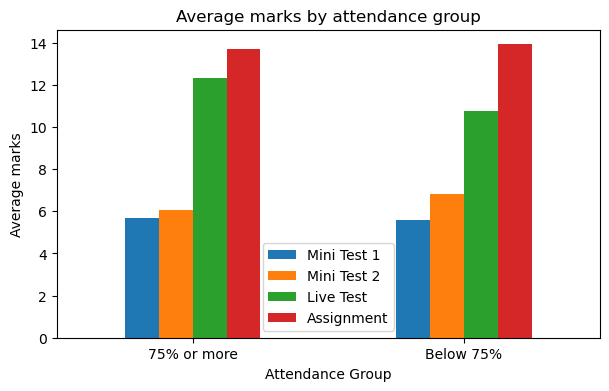

In [64]:
#Impact of attendance on Tests/Assignment marks.
marks_cols = ['Mini Test 1', 'Mini Test 2', 'Live Test', 'Assignment']

# (a) correlation
corr = merge_df[['Attendance %'] + marks_cols].corr()['Attendance %']
print(corr.round(3))

# (b) compare two groups
merge_df['Attendance Group'] = np.where(merge_df['Attendance %'] < 75, 'Below 75%', '75% or more')
print(merge_df.groupby('Attendance Group')[marks_cols].mean().round(2))

# (c) chart
merge_df.groupby('Attendance Group')[marks_cols].mean().plot(kind='bar', figsize=(7, 4))
plt.ylabel('Average marks')
plt.title('Average marks by attendance group')
plt.xticks(rotation=0)
plt.show()

Visualization
1.	Create a bar chart displaying weighted percentages for top 5 students.
2.	Create a pie chart showing the distribution of students across the four performance categories.
3.	Create box plots for each test (Live Test, Mini Test 1, Mini Test 2, Assignment) to visualize the spread and detect potential outliers in scores.
4.	Create a chart to show the students where attendance is less than 50%.
5.	Any other visualization/analysis which you can infer from data for the management.


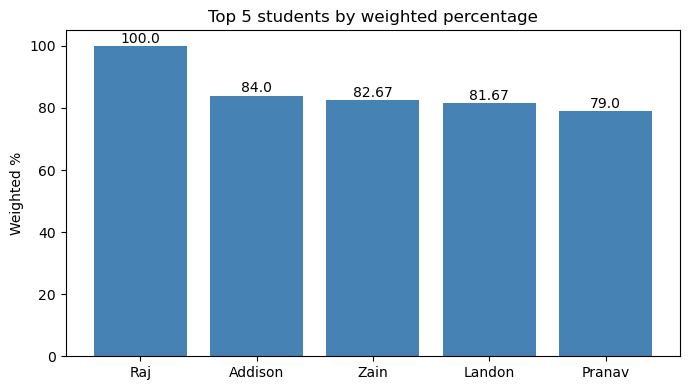

In [65]:
# Bar chart for top 5 students on the basis of weighted %
top5 = merge_df.nlargest(5, 'Weighted %', keep='all')

plt.figure(figsize=(7, 4))
plt.bar(top5['Name'], top5['Weighted %'], color='steelblue')
plt.ylabel('Weighted %')
plt.title('Top 5 students by weighted percentage')
plt.ylim(0, 105)
for i, v in enumerate(top5['Weighted %']):
    plt.text(i, v + 1, str(v), ha='center')
plt.tight_layout()
plt.show()

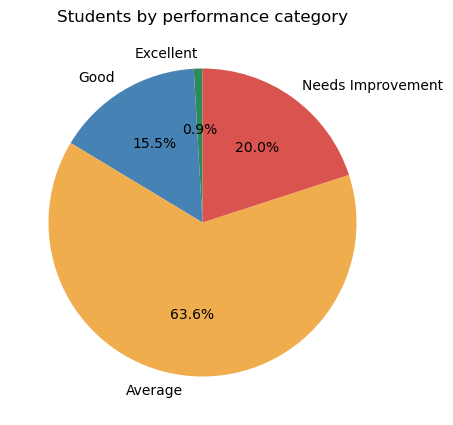

In [66]:
#Create a pie chart showing the distribution of students across the four performance categories.
order = ['Excellent', 'Good', 'Average', 'Needs Improvement']
counts = merge_df['Performance'].value_counts().reindex(order).fillna(0)

plt.figure(figsize=(5, 5))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%',
        colors=['#2e8b57', '#4682b4', '#f0ad4e', '#d9534f'], startangle=90)
plt.title('Students by performance category')
plt.show()

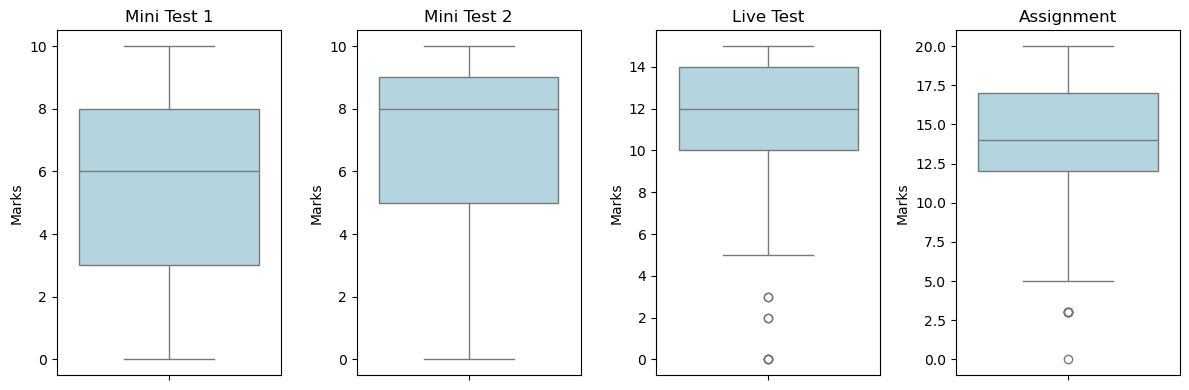

In [67]:
#Create box plots for each test (Live Test, Mini Test 1, Mini Test 2, Assignment) to visualize the spread and detect potential outliers in scores.
marks_cols = ['Mini Test 1', 'Mini Test 2', 'Live Test', 'Assignment']

fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for ax, c in zip(axes, marks_cols):
    sns.boxplot(y=merge_df[c], ax=ax, color='lightblue')
    ax.set_title(c)
    ax.set_ylabel('Marks')
plt.tight_layout()
plt.show()

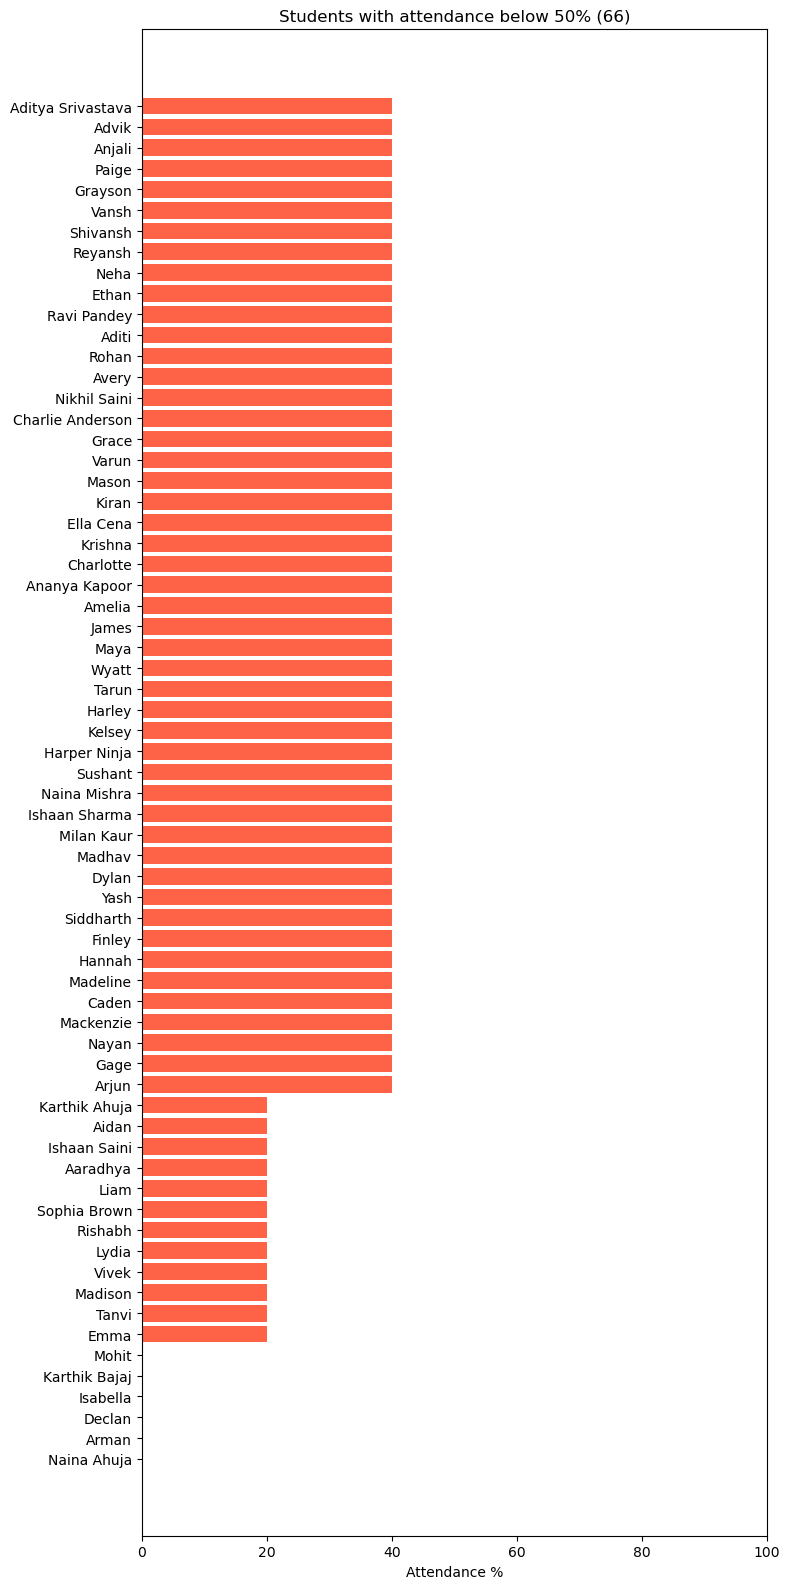

In [68]:
#Create a chart to show the students where attendance is less than 50%.
low = merge_df[merge_df['Attendance %'] < 50].sort_values('Attendance %')

plt.figure(figsize=(8, 16))
plt.barh(low['Name'], low['Attendance %'], color='tomato')
plt.xlabel('Attendance %')
plt.title('Students with attendance below 50% (' + str(len(low)) + ')')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

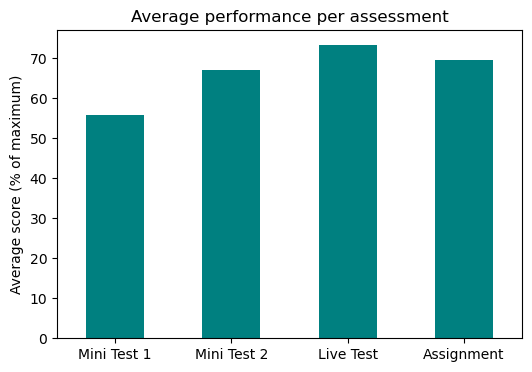

In [69]:
#Any other visualization/analysis which you can infer from data for the management.
max_marks = {'Mini Test 1': 10, 'Mini Test 2': 10, 'Live Test': 15, 'Assignment': 20}
avg_pct = pd.Series({c: merge_df[c].mean() / m * 100 for c, m in max_marks.items()})

avg_pct.plot(kind='bar', color='teal', figsize=(6, 4))
plt.ylabel('Average score (% of maximum)')
plt.title('Average performance per assessment')
plt.xticks(rotation=0)
plt.show()